In [160]:
# # Connection to Drive
# from google.colab import drive
# drive.mount('/content/drive')

# packages
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
from pathlib import Path
import os
import geopandas as gpd
import numpy as np
import shapely
import random
import math
from shapely.geometry import MultiPolygon, Polygon, LineString

### Detect Google Drive

In [ ]:
def find_google_drive():
    home = Path.home()

    # Common Google Drive mount locations
    possible_paths = [
        home / "My Drive",  # Linux or custom mount
        home / "Google Drive",  # Older macOS installations
        home / "Library/CloudStorage",  # macOS
        Path("G:/My Drive"),  # Windows
        Path("H:/My Drive"),  # Alternative Windows drive
    ]

    # Check common locations
    for path in possible_paths:
        if path.name == "CloudStorage":
            matches = list(path.glob("GoogleDrive*/My Drive"))
            if matches:
                return matches[0]

        if path.exists() and path.is_dir():
            if path.name == "My Drive":
                return path

            # Check for nested My Drive
            nested = path / "My Drive"
            if nested.exists():
                return nested

    # Search other Windows drive letters
    for letter in "CDEFGHIJKLMNOPQRSTUVWXYZ":
        path = Path(f"{letter}:/My Drive")
        if path.exists():
            return path

    raise FileNotFoundError(
        "Google Drive not found. Make sure Google Drive is mounted "
        "and accessible through your filesystem."
    )


drive_path = find_google_drive()
print(f"Google Drive found at: {drive_path}")

Google Drive found at: /Users/kmorhun/Google Drive/My Drive


## Load Geojson Files

In [3]:
# Get files
folder_path = drive_path / "11_458_ProjectFolder_2026"
spatial_filepath =  folder_path / "Data" / "processed files"

streets_filepath = spatial_filepath / "streets_mattapan.geojson"
parcels_filepath = spatial_filepath / "parcels_2025_mattapan.geojson"
buildings_filepath = spatial_filepath / "building_footprints_mattapan_with_primary.geojson"

files = os.listdir(folder_path)
print(files)

# load the geojson files in base files:
streets_raw_gdf = gpd.read_file(streets_filepath)
parcels_raw_gdf = gpd.read_file(parcels_filepath)
buildings_raw_gdf = gpd.read_file(buildings_filepath)

# Convert to Mass CRS (2249)
streets_raw_gdf = streets_raw_gdf.to_crs(epsg=2249)
parcels_raw_gdf = parcels_raw_gdf.to_crs(epsg=2249)
buildings_raw_gdf = buildings_raw_gdf.to_crs(epsg=2249)

['Data Bases + Assumptions.gsheet', '.DS_Store', 'Assumptions.gdoc', 'Zoning_Schema', 'Data', 'Class Presentations']


In [4]:
print("Streets")
print(streets_raw_gdf.shape)
print(streets_raw_gdf.crs)
print(streets_raw_gdf.columns)

print("Parcels")
print(parcels_raw_gdf.shape)
print(parcels_raw_gdf.crs)
print(parcels_raw_gdf.columns)

print("Buildings")
print(buildings_raw_gdf.shape)
print(buildings_raw_gdf.crs)
print(buildings_raw_gdf.columns)

Streets
(652, 35)
EPSG:2249
Index(['SEGMENT_ID', 'L_F_ADD', 'L_T_ADD', 'R_F_ADD', 'R_T_ADD', 'STREET_ID',
       'PRE_DIR', 'ST_NAME', 'ST_TYPE', 'SUF_DIR', 'ALTERNATE_', 'CFCC',
       'SPEEDLIMIT', 'ONEWAY', 'F_ZLEV', 'T_ZLEV', 'FT_COST', 'TF_COST',
       'FT_DIR', 'TF_DIR', 'SHIELD', 'HWY_NUM', 'MUN_L', 'MUN_R', 'NBHD_L',
       'NBHD_R', 'STATE00_L', 'STATE00_R', 'COUNTY00_L', 'COUNTY00_R',
       'MCD00_L', 'MCD00_R', 'Shape_Leng', 'shape_wkt', 'geometry'],
      dtype='object')
Parcels
(4488, 82)
EPSG:2249
Index(['MAP_PAR_ID', 'LOC_ID', 'POLY_TYPE', 'MAP_NO', 'SOURCE', 'PLAN_ID',
       'BND_CHK', 'NO_MATCH', 'TOWN_ID', 'last_edite', 'created_us',
       'created_da', 'last_edi_1', 'Shape_Leng', 'Shape_Area', 'shape_wkt',
       'PID', 'CM_ID', 'ST_NUM', 'ST_NUM2', 'ST_NAME', 'UNIT_NUM', 'CITY',
       'ZIP_CODE', 'BLDG_SEQ', 'NUM_BLDGS', 'LUC', 'LU', 'LU_DESC',
       'BLDG_TYPE', 'OWN_OCC', 'OWNER', 'MAIL_ADDRESSEE',
       'MAIL_STREET_ADDRESS', 'MAIL_CITY', 'MAIL_STATE', 'MA

<Axes: >

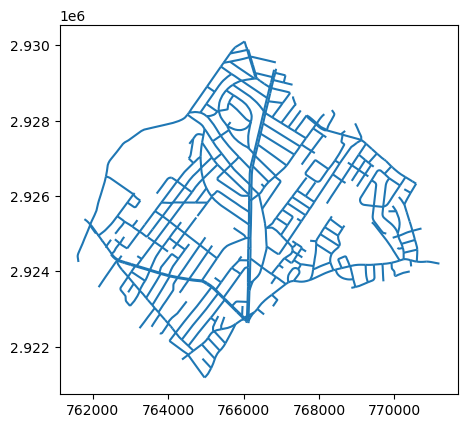

In [5]:
streets_raw_gdf.plot()

<Axes: >

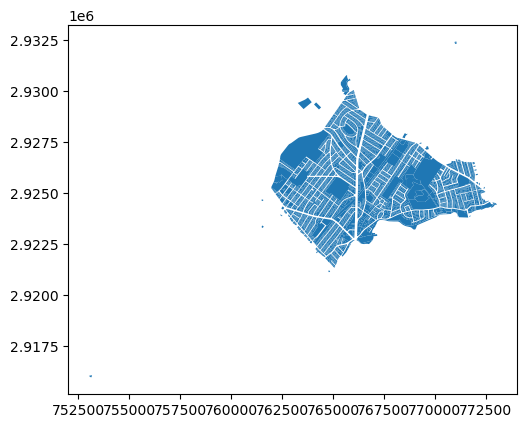

In [6]:
parcels_raw_gdf.plot()

<Axes: >

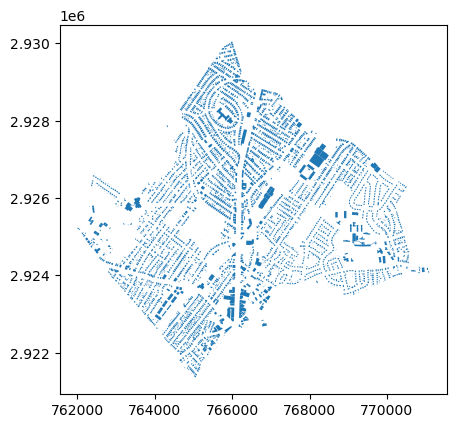

In [7]:
buildings_raw_gdf.plot()

# *START PARCELIZATION*
Run this after loading in the data.

In [8]:
starter_parcel_cols = ['MAP_PAR_ID',
                'ST_NAME',
                'geometry']

# Reduce to basic
cleaned_parcels = parcels_raw_gdf[starter_parcel_cols].copy()
cleaned_parcels['parcel_area'] = cleaned_parcels.area
cleaned_parcels['number_vertices'] = cleaned_parcels['geometry'].apply(lambda x: len(shapely.get_coordinates( x )) )

In [9]:
# Create the bounding box

min_bounding_parcels_gdf = gpd.GeoDataFrame(
    {
        "PARCEL_ID": cleaned_parcels["MAP_PAR_ID"],
        "geometry": cleaned_parcels.geometry.minimum_rotated_rectangle()

    },
    geometry="geometry",
    crs=cleaned_parcels.crs
)

min_bounding_parcels_gdf['AREA'] = min_bounding_parcels_gdf.area

min_bounding_parcels_gdf

,PARCEL_ID,geometry,AREA
0,1803009001,"POLYGON ((765314.996 2925995.425, 765320.009 2...",45.927457
1,1802177000,"POLYGON ((764551.908 2925139.622, 764519.651 2...",6682.459308
2,1801047000,"POLYGON ((765974.656 2924387.811, 765897.479 2...",5737.938887
3,1802778001,"POLYGON ((764079.757 2925173.215, 764162.5 292...",7743.470101
4,1802766000,"POLYGON ((764145.127 2925428.938, 764226.553 2...",4615.018590
...,...,...,...
4483,1704042010,"POLYGON ((771812.3 2924347.029, 771851.961 292...",29140.961088
4484,1704042040,"POLYGON ((771945.827 2924218.164, 771942.567 2...",87.808150
4485,1704042050,"POLYGON ((771960.069 2924135.309, 771949.016 2...",271.175998
4486,1800157000,"POLYGON ((767693.842 2925523.654, 767779.284 2...",2336.879582


In [10]:
# Calculate bounding box ratio
cleaned_parcels['parcel_boundingbox_ratio'] = cleaned_parcels['parcel_area'].to_numpy() / min_bounding_parcels_gdf['AREA'].to_numpy()

# Logic for what is ready to process

rules = {
  #"four_vertices"       :  cleaned_parcels['number_vertices'] == 4,
  "boundingbox_ratio"   :  cleaned_parcels['parcel_boundingbox_ratio'] > 0.9
}
combined_rules = pd.concat(rules, axis=1).all(axis=1)


filtered_parcels = cleaned_parcels.loc[combined_rules].copy()
filtered_parcels

print(f'filtered_parcels contains {100*len(filtered_parcels)/len(cleaned_parcels)}%')
#cleaned_parcels[ cleaned_parcels['ready_to_process'] == 1 ]


filtered_parcels contains 74.66577540106952%


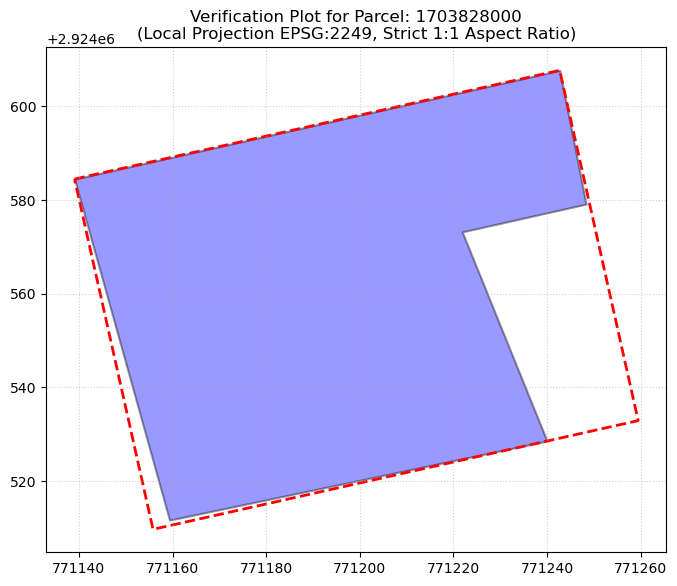

In [ ]:
# PRINT A RANDOM PARCEL AND BOUNDING BOX

# Select a random parcel ID from those with valid geometries
random_id = random.choice(cleaned_parcels['MAP_PAR_ID'].dropna().values)

# Retrieve parcel and matching bounding box
parcel_geom = cleaned_parcels[cleaned_parcels['MAP_PAR_ID'] == random_id].to_crs(epsg=2249)
bbox_geom = min_bounding_parcels_gdf[min_bounding_parcels_gdf['PARCEL_ID'] == random_id].to_crs(epsg=2249)

# Create a square plot
fig, ax = plt.subplots(figsize=(8, 8))

# Plot actual parcel (semi-transparent blue with solid black border)
parcel_geom.plot(ax=ax, facecolor='blue', alpha=0.4, edgecolor='black', linewidth=1.5, label='Parcel')

# Plot minimum rotated bounding box (dashed red line)
if not bbox_geom.empty:
    bbox_geom.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2, linestyle='--', label='Bounding Box')

# Force a strict 1:1 equal aspect ratio to ensure no visual skewing
ax.set_aspect('equal', adjustable='box')

ax.set_title(f"Verification Plot for Parcel: {random_id}\n(Local Projection EPSG:2249, Strict 1:1 Aspect Ratio)", fontsize=12)
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

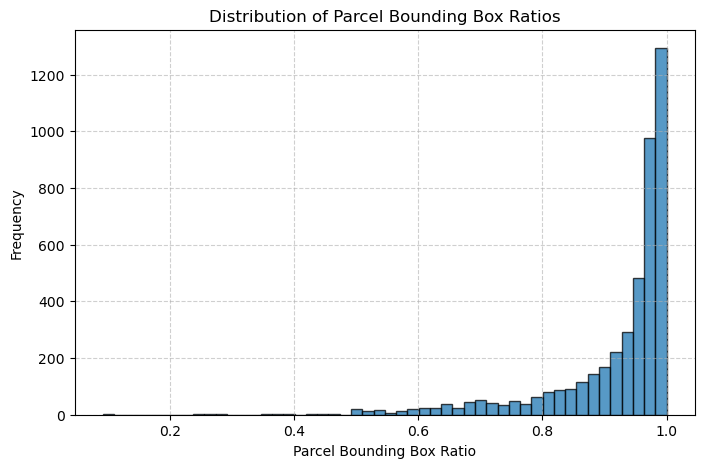

In [ ]:
# Create a histogram of parcel_boundingbox_ratio values
plt.figure(figsize=(8, 5))
plt.hist(cleaned_parcels['parcel_boundingbox_ratio'].dropna(), bins=50, edgecolor='black', alpha=0.75)
plt.title('Distribution of Parcel Bounding Box Ratios')
plt.xlabel('Parcel Bounding Box Ratio')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

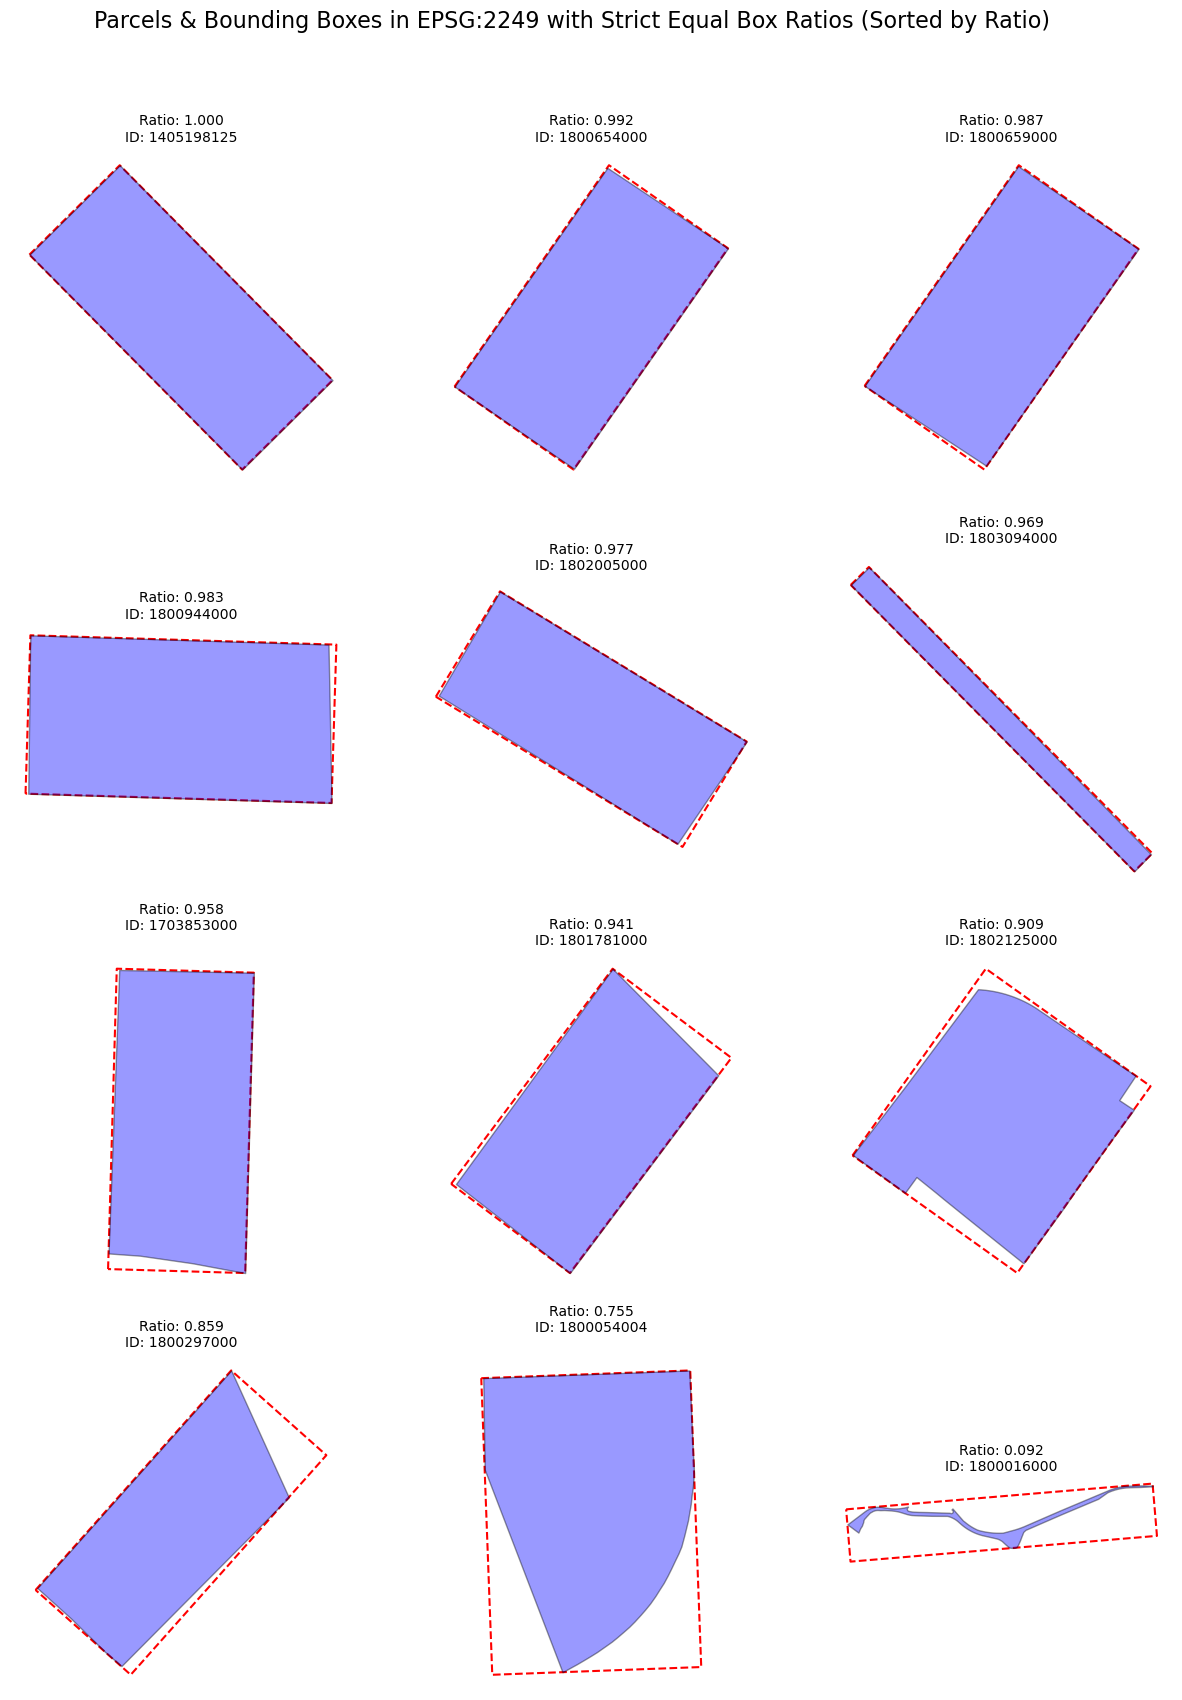

In [ ]:
# Select a representative sample of 12 parcels across the ratio range to display in a grid
sample_parcels = cleaned_parcels.dropna(subset=['parcel_boundingbox_ratio']).sort_values(by='parcel_boundingbox_ratio', ascending=False)

# Let's take 12 evenly spaced indices from the sorted list to show a variety of ratios from high to low
indices = np.linspace(0, len(sample_parcels) - 1, 12, dtype=int)
selected_sample = sample_parcels.iloc[indices]

fig, axes = plt.subplots(4, 3, figsize=(15, 20))
axes = axes.flatten()

for i, (idx, row) in enumerate(selected_sample.iterrows()):
    ax = axes[i]

    # Get matching bounding box
    bbox_row = min_bounding_parcels_gdf[min_bounding_parcels_gdf['PARCEL_ID'] == row['MAP_PAR_ID']]

    # Convert both to the local state plane projection (EPSG:2249) which is highly conformal and accurate locally
    parcel_gdf_projected = gpd.GeoDataFrame([row], geometry='geometry', crs=cleaned_parcels.crs).to_crs(epsg=2249)

    # Plot bounding box (in red dotted outline) projected to EPSG:2249
    if not bbox_row.empty:
        bbox_gdf_projected = bbox_row.to_crs(epsg=2249)
        bbox_gdf_projected.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1.5, linestyle='--', label='Bounding Box')

    # Plot actual parcel (in semi-transparent blue) projected to EPSG:2249
    parcel_gdf_projected.plot(ax=ax, facecolor='blue', alpha=0.4, edgecolor='black', label='Parcel')

    # Enforce strict equal physical aspect ratio of the plot box
    ax.set_aspect('equal', adjustable='box')

    ratio = row['parcel_boundingbox_ratio']
    ax.set_title(f"Ratio: {ratio:.3f}\nID: {row['MAP_PAR_ID']}", fontsize=10)
    ax.axis('off')

plt.suptitle('Parcels & Bounding Boxes in EPSG:2249 with Strict Equal Box Ratios (Sorted by Ratio)', fontsize=16, y=0.95)
plt.show()

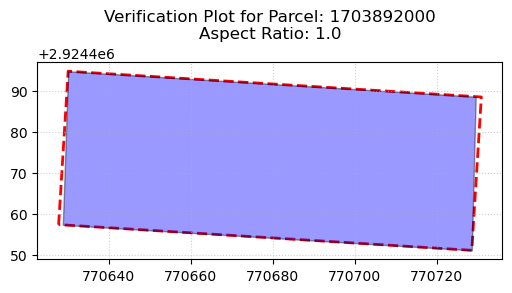

In [16]:
# Verification: Retrieve one parcel bounding box, plot it, and print its aspect ratio settings
sample_parcel_id = "1703892000"  # An example ID from the sorted list
bbox_geom = min_bounding_parcels_gdf[min_bounding_parcels_gdf['PARCEL_ID'] == sample_parcel_id].to_crs(epsg=2249)
parcel_geom = cleaned_parcels[cleaned_parcels['MAP_PAR_ID'] == sample_parcel_id].to_crs(epsg=2249)

fig, ax = plt.subplots(figsize=(6, 6))
if not bbox_geom.empty:
    bbox_geom.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2, linestyle='--', label='Bounding Box')
if not parcel_geom.empty:
    parcel_geom.plot(ax=ax, facecolor='blue', alpha=0.4, edgecolor='black', label='Parcel')

# Enforce aspect ratio
ax.set_aspect('equal', adjustable='box')
ax.set_title(f"Verification Plot for Parcel: {sample_parcel_id}\nAspect Ratio: {ax.get_aspect()}")
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [17]:
min_bounding_parcels_gdf

,PARCEL_ID,geometry,AREA
0,1803009001,"POLYGON ((765314.996 2925995.425, 765320.009 2...",45.927457
1,1802177000,"POLYGON ((764551.908 2925139.622, 764519.651 2...",6682.459308
2,1801047000,"POLYGON ((765974.656 2924387.811, 765897.479 2...",5737.938887
3,1802778001,"POLYGON ((764079.757 2925173.215, 764162.5 292...",7743.470101
4,1802766000,"POLYGON ((764145.127 2925428.938, 764226.553 2...",4615.018590
...,...,...,...
4483,1704042010,"POLYGON ((771812.3 2924347.029, 771851.961 292...",29140.961088
4484,1704042040,"POLYGON ((771945.827 2924218.164, 771942.567 2...",87.808150
4485,1704042050,"POLYGON ((771960.069 2924135.309, 771949.016 2...",271.175998
4486,1800157000,"POLYGON ((767693.842 2925523.654, 767779.284 2...",2336.879582


In [18]:
min_bounding_parcels_gdf

,PARCEL_ID,geometry,AREA
0,1803009001,"POLYGON ((765314.996 2925995.425, 765320.009 2...",45.927457
1,1802177000,"POLYGON ((764551.908 2925139.622, 764519.651 2...",6682.459308
2,1801047000,"POLYGON ((765974.656 2924387.811, 765897.479 2...",5737.938887
3,1802778001,"POLYGON ((764079.757 2925173.215, 764162.5 292...",7743.470101
4,1802766000,"POLYGON ((764145.127 2925428.938, 764226.553 2...",4615.018590
...,...,...,...
4483,1704042010,"POLYGON ((771812.3 2924347.029, 771851.961 292...",29140.961088
4484,1704042040,"POLYGON ((771945.827 2924218.164, 771942.567 2...",87.808150
4485,1704042050,"POLYGON ((771960.069 2924135.309, 771949.016 2...",271.175998
4486,1800157000,"POLYGON ((767693.842 2925523.654, 767779.284 2...",2336.879582


In [ ]:
cleaned_parcels['is_four_sided'] =

SyntaxError: invalid syntax (1016776536.py, line 1)

In [ ]:
def tag_four_sided(gdf):

  for idx, row in gdf.iterrows():


parcels_gdf



,MAP_PAR_ID,LOC_ID,POLY_TYPE,MAP_NO,SOURCE,PLAN_ID,BND_CHK,NO_MATCH,TOWN_ID,last_edite,...,KITCHEN_STYLE3,HEAT_TYPE,HEAT_SYSTEM,AC_TYPE,FIREPLACES,ORIENTATION,NUM_PARKING,PROP_VIEW,CORNER_UNIT,geometry
0,1803009001,F_765315_2926000,FEE,18,ASSESS,None,None,N,35,2024-09-17,...,,,,,0,,,,,"MULTIPOLYGON (((-71.09669 42.27637, -71.0967 4..."
1,1802177000,F_764586_2925079,FEE,18,ASSESS,None,None,N,35,2024-09-17,...,,F - Forced Hot Air,,C - Central AC,1,,1,A - Average,,"MULTIPOLYGON (((-71.09927 42.27388, -71.09915 ..."
2,1801047000,F_765943_2924345,FEE,18,ASSESS,None,None,N,35,2024-09-17,...,,F - Forced Hot Air,,N - None,0,,2,A - Average,,"MULTIPOLYGON (((-71.09429 42.27194, -71.09429 ..."
3,1802778001,F_764143_2925171,FEE,18,ASSESS,None,None,N,35,2024-09-17,...,,F - Forced Hot Air,,C - Central AC,1,,2,A - Average,,"MULTIPOLYGON (((-71.10096 42.27396, -71.10127 ..."
4,1802766000,F_764199_2925417,FEE,18,ASSESS,None,None,N,35,2024-09-17,...,,F - Forced Hot Air,,N - None,0,,2,A - Average,,"MULTIPOLYGON (((-71.10062 42.27477, -71.10072 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4483,1704042010,F_771921_2924167,FEE,17,ASSESS,None,None,N,35,2024-09-17,...,,F - Forced Hot Air,I - Indiv. Cntrl,C - Central AC,0,F - Front/Street,2,A - Average,N - No,"MULTIPOLYGON (((-71.0725 42.27176, -71.07248 4..."
4484,1704042040,F_771946_2924202,FEE,17,ASSESS,None,None,N,35,2024-09-17,...,,,,,,,,,,"MULTIPOLYGON (((-71.07221 42.27133, -71.07222 ..."
4485,1704042050,F_771952_2924163,FEE,17,ASSESS,None,None,N,35,2024-09-17,...,,,,,,,,,,"MULTIPOLYGON (((-71.07217 42.27118, -71.07219 ..."
4486,1800157000,F_767743_2925503,FEE,18,ASSESS,None,None,N,35,2024-09-17,...,,,,,0,,,,,"MULTIPOLYGON (((-71.08755 42.27493, -71.08757 ..."


## Decomposing and Classifying Parcel Edges

In [ ]:
def decompose_parcel_edges(parcels_gdf):
    """
    Decompose each parcel's minimum rotated bounding rectangle
    into four edge LineStrings.

    Returns a GeoDataFrame with one row per edge.
    """
    records = []

    for _, parcel in parcels_gdf.iterrows():
        parcel_id = parcel["MAP_PAR_ID"]
        parcel_geom = parcel.geometry

        if parcel_geom is None or parcel_geom.is_empty:
            continue

        # Minimum rotated bounding rectangle
        bbox = parcel_geom.minimum_rotated_rectangle

        if bbox.geom_type != "Polygon":
            continue

        coords = list(bbox.exterior.coords)

        # Four sides; exterior coordinates have a repeated endpoint
        for edge_num in range(4):
            start = coords[edge_num]
            end = coords[edge_num + 1]

            edge_geom = LineString([start, end])

            records.append({
                "MAP_PAR_ID": parcel_id,
                "edge_num": edge_num,
                "edge_length": edge_geom.length,
                "geometry": edge_geom
            })

    # Create a new GeoDataFrame for the edges, explicitly specifying the geometry column
    return gpd.GeoDataFrame(
        records,
        geometry="geometry",
        crs=parcels_gdf.crs
    )


### Detour: How to match street names between parcel data and street data?

In [56]:
streets_temp = streets_raw_gdf.copy()
streets_temp["street_match"] = (
    streets_temp["ST_NAME"].fillna("").str.strip().str.upper()
)

cleaned_parcels_temp = cleaned_parcels.copy()
cleaned_parcels_temp["street_match"] = (
    cleaned_parcels_temp["ST_NAME"].fillna("").str.strip().str.upper()
)

# try removing the last word from the street names in parcels to see if that helps with matching
cleaned_parcels_temp["street_match"] = cleaned_parcels_temp["street_match"].apply(lambda x: " ".join(x.split()[:-1]) if len(x.split()) > 1 else x)

# Test how many of the street names match
print("Number of matching street names in parcels:")
print(cleaned_parcels_temp["street_match"].isin(streets_temp["street_match"]).sum(), "out of", len(cleaned_parcels_temp), "parcels.")

# order both alphabetically to compare some similarity
streets_temp = streets_temp.sort_values("street_match")
cleaned_parcels_temp = cleaned_parcels_temp.sort_values("street_match")
print("Street names in parcels:")
print(cleaned_parcels_temp["street_match"].head(500).unique().tolist())
print("Street names in streets:")
print(streets_temp["street_match"].head(500).unique().tolist())

Number of matching street names in parcels:
3954 out of 4488 parcels.
Street names in parcels:
['ALABAMA', 'ALMONT', 'ANNAFRAN', 'ARBORCREST', 'ASTORIA', 'BABSON', 'BANFIELD', 'BISMARCK', 'BLUE HILL', 'BLUE JAY', 'BLUEFIELD', 'BRADFORD', 'BRIARCLIFF', 'BROCKTON', 'BURMAH', 'CADDY']
Street names in streets:
['ALABAMA', 'ALMONT', 'ARBORCREST', 'ASHTON', 'ASTORIA', 'BABSON', 'BAIRD', 'BANFIELD', 'BISMARCK', 'BLAKE', 'BLUE HILL', 'BLUE HILLS', 'BLUEFIELD', 'BRADFORD', 'BRIARCLIFF', 'BROCKTON', 'BURMAH', 'CANAAN', 'CATON', 'CHESTER', 'CLARKWOOD', 'COLORADO', 'CONSTITUTION', 'COOKSON', 'CORBET', 'CORMAN', 'COURTLAND', 'CRAGMERE', 'CROSSMAN', 'CROYDON', 'CULBERT', 'CUMMINS', 'CURRIER', 'DANIA', 'DAVID LOPES FOOTWAY', 'DEERING', 'DELHI', 'DELNORE', 'DESMOND', 'DONWOOD', 'DOONE', 'DR. MARY MOORE BEATTY', 'DUKE', 'DUKE STREET FOOTWAY', 'DUXBURY', 'EDGEWATER', 'ELENE', 'ELIZABETH', 'ERROL', 'ESKRIDGE', 'ESTELLA', 'EVANS', 'EVELYN', 'FAIRLAWN', 'FAIRWAY', 'FAUNCE', 'FAVRE', 'FESSENDEN', 'FLINT', '

In [97]:
SUFFIXES = {
    'ST', 'STREET', 'AVE', 'AVENUE', 'RD', 'ROAD', 'DR', 'DRIVE',
    'LN', 'LANE', 'CT', 'COURT', 'PL', 'PLACE', 'TE', 'TERRACE',
    'PKWY', 'PARKWAY', 'HWY', 'HIGHWAY', 'SQ', 'SQUARE', 'CIR', 'CIRCLE',
} | set(streets_raw_gdf["ST_TYPE"].dropna().unique())
# get the list of suffixes from the streets_raw_gdf in ST_TYPE
print("Street suffixes found in streets_raw_gdf:", SUFFIXES)

def normalize_street_name(name):
    if name is None:
        return ""

    parts = str(name).strip().upper().replace('.', '').split()
    if len(parts) > 1 and parts[-1] in SUFFIXES:
        parts = parts[:-1]

    return " ".join(parts)

# test effectiveness of normalization function by applying to parcels and streets and counting matches
parcel_names = cleaned_parcels["ST_NAME"].dropna().unique()
street_names = streets_raw_gdf["ST_NAME"].dropna().unique()

matches = 0
for p_name in parcel_names:
    for s_name in street_names:
        if normalize_street_name(p_name) == normalize_street_name(s_name):
            matches += 1

print(f"Number of matching normalized names: {matches} out of {len(parcel_names)} parcel names and {len(street_names)} street names.")

Street suffixes found in streets_raw_gdf: {'ROAD', 'HWY', 'AVENUE', 'PARKWAY', 'ST', 'TER', 'WAY', 'PARK', 'PL', 'PKWY', 'LANE', 'HIGHWAY', 'CIRCLE', 'RD', 'CIR', 'SQUARE', 'TERRACE', 'COURT', 'CT', 'DR', 'STREET', 'LN', 'PLACE', 'SQ', 'TE', 'AVE', 'DRIVE'}
Number of matching normalized names: 138 out of 189 parcel names and 183 street names.


In [107]:
import geopandas as gpd
import numpy as np
from shapely.geometry import LineString, MultiLineString

def classify_parcel_edges(
    parcel_edges_gdf,
    parcels_gdf,
    streets_gdf
):
    """
    Classify parcel bounding-box edges as front, back, side_1, or side_2.

    The front edge is selected by matching the parcel's street name
    to nearby street geometry and evaluating distance and parallelism.

    Parameters
    ----------
    parcel_edges_gdf : GeoDataFrame
        Output from decompose_parcel_edges().
    parcels_gdf : GeoDataFrame
        Original parcel polygons, including MAP_PAR_ID and ST_NAME.
    streets_gdf : GeoDataFrame
        Street geometries, including street name information.

    Returns
    -------
    GeoDataFrame
        Parcel edges with an edge_type classification.
    """

    results = []

    # Match parcel IDs to their street names
    parcel_street_names = (
        parcels_gdf
        .set_index("MAP_PAR_ID")["ST_NAME"]
        .to_dict()
    )

    # Ensure street geometries are in the same CRS
    if parcel_edges_gdf.crs != streets_gdf.crs:
        streets_gdf = streets_gdf.to_crs(parcel_edges_gdf.crs)

    def get_line_parts(geom):
        """Return individual LineStrings from a line or multipart geometry."""
        if geom is None or geom.is_empty:
            return []

        if geom.geom_type == "LineString":
            return [geom]

        if geom.geom_type == "MultiLineString":
            return list(geom.geoms)

        if geom.geom_type == "GeometryCollection":
            parts = []
            for part in geom.geoms:
                parts.extend(get_line_parts(part))
            return parts

        return []

    def parallel_alignment(edge, street):
        """
        Calculate how parallel an edge is to a street.
        Returns a value between 0 and 1.
        """
        edge_coords = list(edge.coords)

        ex = edge_coords[-1][0] - edge_coords[0][0]
        ey = edge_coords[-1][1] - edge_coords[0][1]

        edge_length = np.hypot(ex, ey)

        if edge_length == 0:
            return 0

        # Find the point on the street nearest the edge midpoint
        midpoint = edge.interpolate(0.5, normalized=True)
        projected_distance = street.project(midpoint)

        # Sample points on either side of the nearest point
        delta = min(5, street.length / 2)

        if delta <= 0:
            return 0

        p1 = street.interpolate(max(0, projected_distance - delta))
        p2 = street.interpolate(min(street.length, projected_distance + delta))

        sx = p2.x - p1.x
        sy = p2.y - p1.y

        street_length = np.hypot(sx, sy)

        if street_length == 0:
            return 0

        # Absolute dot product: 1 = parallel, 0 = perpendicular
        return abs((ex * sx + ey * sy) /
                   (edge_length * street_length))

    # Process each parcel independently
    for parcel_id, edges in parcel_edges_gdf.groupby("MAP_PAR_ID"):

        street_name = parcel_street_names.get(parcel_id)

        # Find matching street records
        normalized_parcel_name = normalize_street_name(street_name)

        matching_streets = streets_gdf[
            streets_gdf["ST_NAME"].apply(normalize_street_name)
            == normalized_parcel_name
        ]

        # Expand matching street geometries into individual LineStrings
        street_lines = []

        for geom in matching_streets.geometry:
            street_lines.extend(get_line_parts(geom))

        edge_scores = []

        for idx, edge_row in edges.iterrows():

            edge_geom = edge_row.geometry

            best_score = float("inf")

            for street_geom in street_lines:

                distance = edge_geom.distance(street_geom)

                alignment = parallel_alignment(
                    edge_geom,
                    street_geom
                )

                # Ignore streets that are too far away or poorly aligned
                if distance > 100 or alignment < 0.7:
                    continue

                # Lower score is better
                score = distance + (1 - alignment) * 20

                if score < best_score:
                    best_score = score

            edge_scores.append((idx, best_score))

        # Select the edge with the best street match as the front
        valid_scores = [
            (idx, score)
            for idx, score in edge_scores
            if score != float("inf")
        ]

        if valid_scores:
            front_idx, _ = min(valid_scores, key=lambda x: x[1])

            # Bounding rectangle edges are ordered cyclically.
            # The edge opposite the front is two positions away.
            edge_numbers = edges["edge_num"].tolist()
            front_edge_num = edges.loc[front_idx, "edge_num"]
            back_edge_num = (front_edge_num + 2) % 4

            for idx, row in edges.iterrows():

                edge_num = row["edge_num"]

                if idx == front_idx:
                    edge_type = "front"
                elif edge_num == back_edge_num:
                    edge_type = "back"
                elif edge_num == (front_edge_num + 1) % 4:
                    edge_type = "side_1"
                else:
                    edge_type = "side_2"

                results.append({
                    **row.drop(labels="geometry").to_dict(),
                    "edge_type": edge_type,
                    "geometry": row.geometry
                })

        else:
            # No street match: leave all edges unclassified
            for idx, row in edges.iterrows():
                results.append({
                    **row.drop(labels="geometry").to_dict(),
                    "edge_type": "unknown",
                    "geometry": row.geometry
                })

    return gpd.GeoDataFrame(
        results,
        geometry="geometry",
        crs=parcel_edges_gdf.crs
    )

In [108]:
# Process all parcels and aggregate edges into one unified layer
parcel_edges_gdf = decompose_parcel_edges(cleaned_parcels)

classified_edges_gdf = classify_parcel_edges(
    parcel_edges_gdf,
    cleaned_parcels,
    streets_raw_gdf
)

# Display the count of decomposed edges grouped by type
print(f"Total parcel edge segments extracted: {len(parcel_edges_gdf)}")
if not parcel_edges_gdf.empty:
    display(parcel_edges_gdf.head(12))

/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.p

Total parcel edge segments extracted: 17952


/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/measurement.py:81: RuntimeWarning: invalid value encountered in distance
  return lib.distance(a, b, **kwargs)


,MAP_PAR_ID,edge_num,edge_length,geometry
0,1803009001,0,8.376382,"LINESTRING (765314.996 2925995.425, 765320.009..."
1,1803009001,1,5.482971,"LINESTRING (765320.009 2926002.135, 765315.617..."
2,1803009001,2,8.376382,"LINESTRING (765315.617 2926005.417, 765310.604..."
3,1803009001,3,5.482971,"LINESTRING (765310.604 2925998.706, 765314.996..."
4,1802177000,0,52.833371,"LINESTRING (764551.908 2925139.622, 764519.651..."
5,1802177000,1,126.481789,"LINESTRING (764519.651 2925097.779, 764619.823..."
6,1802177000,2,52.833371,"LINESTRING (764619.823 2925020.557, 764652.08 ..."
7,1802177000,3,126.481789,"LINESTRING (764652.08 2925062.4, 764551.908 29..."
8,1801047000,0,77.205909,"LINESTRING (765974.656 2924387.811, 765897.479..."
9,1801047000,1,74.319944,"LINESTRING (765897.479 2924389.907, 765895.461..."


### Visualize parcel edges

In [ ]:
from shapely.validation import make_valid

def plot_parcel_edges(
    parcel_id,
    classified_edges_gdf,
    parcels_gdf,
    streets_gdf,
    buffer_distance=100,
    ax=None
):
    """
    Plot one parcel, classified edges, nearby roads,
    and street name labels.
    """

    # Retrieve parcel and edges
    parcel = parcels_gdf[
        parcels_gdf["MAP_PAR_ID"] == parcel_id
    ].copy()

    edges = classified_edges_gdf[
        classified_edges_gdf["MAP_PAR_ID"] == parcel_id
    ]

    if parcel.empty or edges.empty:
        print(f"Parcel {parcel_id} not found or has no edges.")
        return

    # Check parcel geometry
    parcel_geom = parcel.geometry.iloc[0]

    if parcel_geom is None or parcel_geom.is_empty:
        print(f"Parcel {parcel_id} has empty geometry.")
        return

    if not parcel_geom.is_valid:
        parcel_geom = make_valid(parcel_geom)
        parcel.loc[parcel.index[0], "geometry"] = parcel_geom

    if parcel_geom.is_empty:
        print(f"Parcel {parcel_id} could not be repaired.")
        return

    parcel_street_name = parcel["ST_NAME"].iloc[0]

    # Reproject roads BEFORE spatial operations
    roads_gdf = streets_gdf.to_crs(parcel.crs).copy()

    # Remove missing, empty, and invalid road geometries
    valid_roads = (
        roads_gdf.geometry.notna()
        & ~roads_gdf.geometry.is_empty
        & roads_gdf.geometry.is_valid
    )

    roads_gdf = roads_gdf.loc[valid_roads].copy()

    # Find roads within the parcel buffer
    search_area = parcel_geom.buffer(buffer_distance)

    roads = roads_gdf[
        roads_gdf.geometry.intersects(search_area)
    ].copy()

    # Create axes
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))

    # Plot roads only if available
    if not roads.empty:
        roads.plot(
            ax=ax,
            color="gray",
            linewidth=1.5,
            zorder=1
        )

    # Plot parcel
    parcel.plot(
        ax=ax,
        facecolor="lightblue",
        edgecolor="black",
        alpha=0.4,
        linewidth=2,
        zorder=2
    )

    # Plot classified edges
    edge_colors = {
        "front": "green",
        "back": "red",
        "side_1": "orange",
        "side_2": "pink",
        "unknown": "purple"
    }

    for edge_type, color in edge_colors.items():

        subset = edges[edges["edge_type"] == edge_type]

        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                linewidth=4,
                label=edge_type.title(),
                zorder=3
            )

    # Label nearby streets
    for _, road in roads.iterrows():

        road_name = road.get("ST_NAME")

        if not isinstance(road_name, str) or not road_name.strip():
            continue

        geom = road.geometry

        # Handle multipart geometries
        if geom.geom_type == "MultiLineString":
            geom = max(geom.geoms, key=lambda g: g.length)

        if geom.geom_type != "LineString" or geom.is_empty:
            continue

        midpoint = geom.interpolate(0.5, normalized=True)

        ax.annotate(
            road_name,
            xy=(midpoint.x, midpoint.y),
            fontsize=7,
            color="dimgray",
            ha="center",
            va="center",
            bbox=dict(
                facecolor="white",
                alpha=0.7,
                edgecolor="none",
                pad=1
            ),
            zorder=4
        )

    # Title
    ax.set_title(
        f"Parcel: {parcel_id}\nParcel Street: {parcel_street_name}",
        fontsize=10
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

    return ax

In [ ]:
def plot_random_parcels(
    classified_edges_gdf,
    parcels_gdf,
    streets_gdf,
    sample_size=12,
    columns=3,
    buffer_distance=100,
    random_state=None
):
    """
    Randomly select and plot multiple parcels in a subplot grid.
    """

    # Get parcel IDs that have classified edges
    available_ids = (
        classified_edges_gdf["MAP_PAR_ID"]
        .dropna()
        .unique()
    )

    # Sample without replacement
    sample_size = min(sample_size, len(available_ids))

    rng = random.Random(random_state)
    selected_ids = rng.sample(list(available_ids), sample_size)

    # Set up subplot grid
    rows = math.ceil(sample_size / columns)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(columns * 6, rows * 6),
        squeeze=False
    )

    axes = axes.flatten()

    # Plot each parcel
    for i, parcel_id in enumerate(selected_ids):

        plot_parcel_edges(
            parcel_id=parcel_id,
            classified_edges_gdf=classified_edges_gdf,
            parcels_gdf=parcels_gdf,
            streets_gdf=streets_gdf,
            buffer_distance=buffer_distance,
            ax=axes[i]
        )

    # Hide unused subplot axes
    for i in range(sample_size, len(axes)):
        axes[i].set_visible(False)

    # Add shared legend
    legend_items = [
        plt.Line2D([0], [0], color="gray", lw=2, label="Roads"),
        plt.Line2D([0], [0], color="green", lw=4, label="Front"),
        plt.Line2D([0], [0], color="red", lw=4, label="Back"),
        plt.Line2D([0], [0], color="orange", lw=4, label="Side 1"),
        plt.Line2D([0], [0], color="pink", lw=4, label="Side 2"),
        plt.Line2D([0], [0], color="purple", lw=4, label="Unknown")
    ]

    fig.legend(
        handles=legend_items,
        loc="lower center",
        ncol=5,
        bbox_to_anchor=(0.5, 0.01)
    )

    fig.suptitle(
        f"Random Sample of {sample_size} Parcel Classifications",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()

    return selected_ids

/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: 

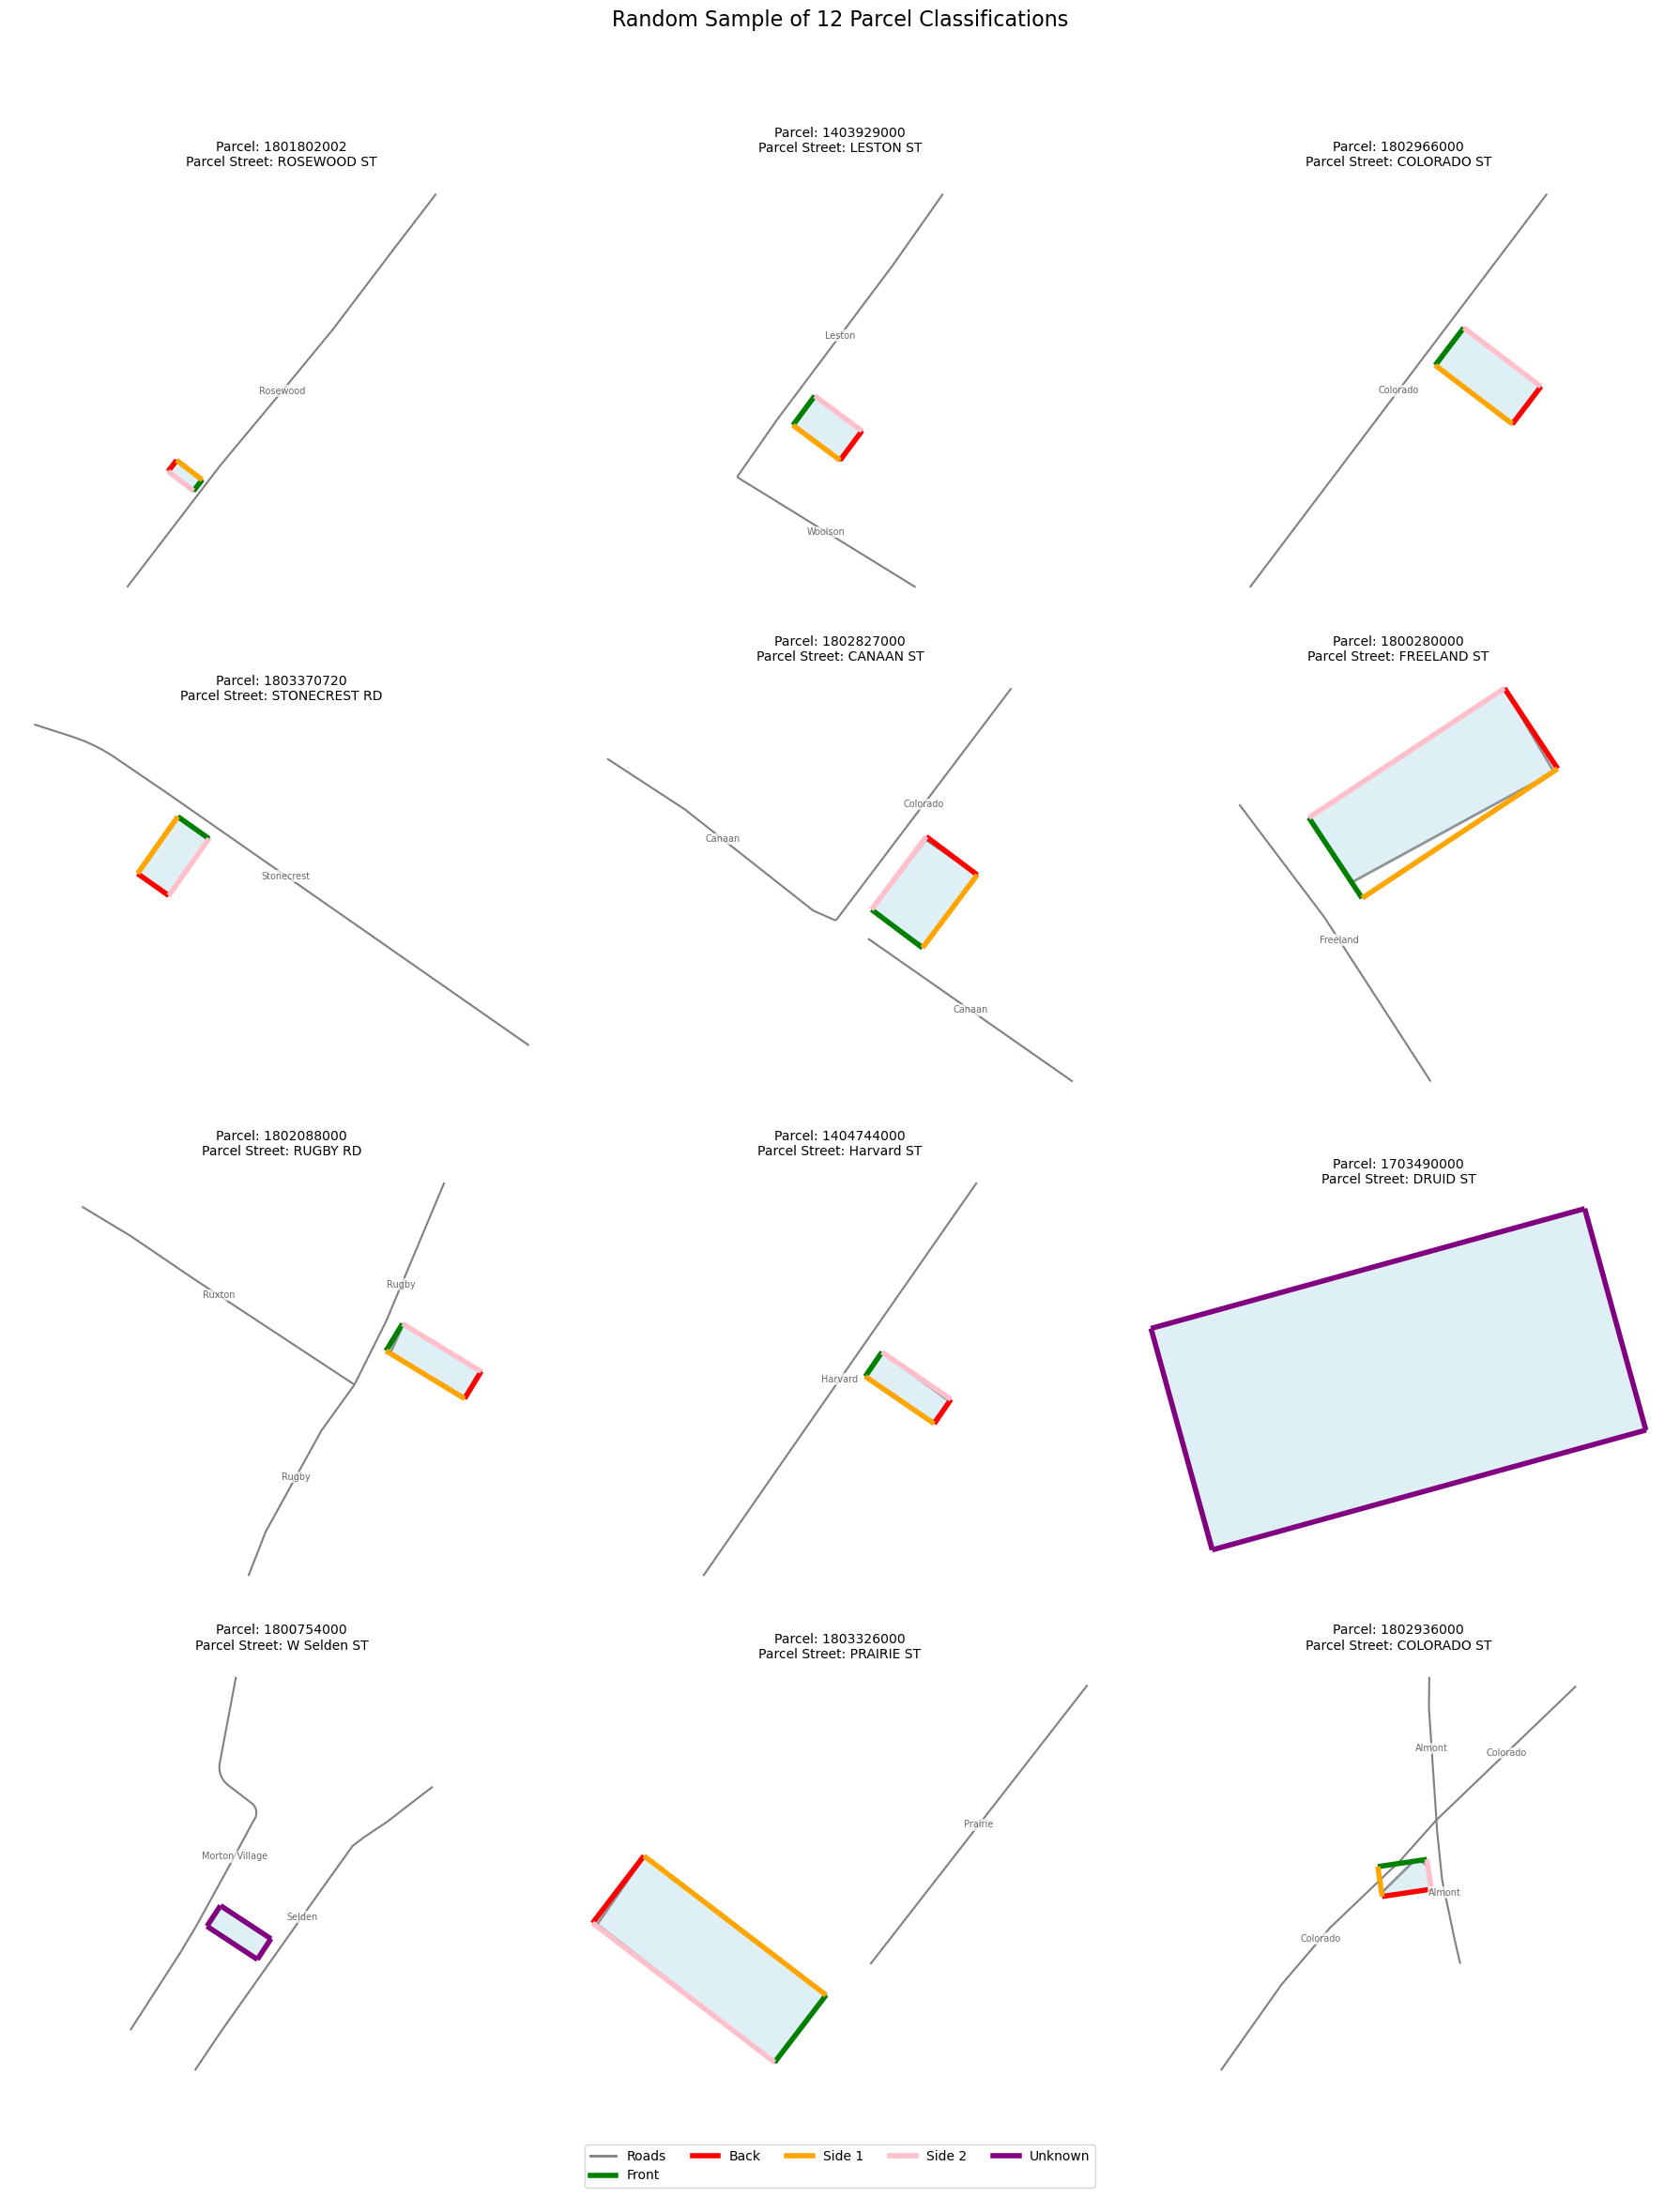

In [114]:
selected_parcel_ids = plot_random_parcels(
    classified_edges_gdf=classified_edges_gdf,
    parcels_gdf=cleaned_parcels,
    streets_gdf=streets_raw_gdf,
    sample_size=12,
    columns=3,
    buffer_distance=100,
    # random_state=42
)

In [106]:
#percent of parcels that have a front edge classified
classified_front_edges = classified_edges_gdf[classified_edges_gdf["edge_type"] == "front"]
unique_front_parcel_ids = classified_front_edges["MAP_PAR_ID"].nunique()
total_parcel_ids = cleaned_parcels["MAP_PAR_ID"].nunique()
print(f"Percentage of all parcels with a front edge classified: {unique_front_parcel_ids / total_parcel_ids * 100:.2f}%")

# identify percentage of filtered parcels that have a front edge classified
filtered_parcel_ids = filtered_parcels["MAP_PAR_ID"].unique()
filtered_front_edges = classified_front_edges[classified_front_edges["MAP_PAR_ID"].isin(filtered_parcel_ids)]
unique_filtered_front_parcel_ids = filtered_front_edges["MAP_PAR_ID"].nunique()
total_filtered_parcel_ids = len(filtered_parcel_ids)
print(f"Percentage of filtered parcels with a front edge classified: {unique_filtered_front_parcel_ids / total_filtered_parcel_ids * 100:.2f}%")


Percentage of all parcels with a front edge classified: 72.15%
Percentage of filtered parcels with a front edge classified: 75.20%


In [81]:
# why parcel 1404825000 did not get a street match?
parcel_1404825000 = cleaned_parcels[cleaned_parcels['MAP_PAR_ID'] == '1404825000'][['MAP_PAR_ID', 'ST_NAME', 'geometry']]
print(parcel_1404825000)

# find the corresponding street name in streets_raw_gdf (not exactly)
maybe_matches = streets_raw_gdf[streets_raw_gdf["ST_NAME"].str.contains("wellington", case=False, na=False)]
print("Potential street matches for 'Wellington':")
print(maybe_matches)


      MAP_PAR_ID             ST_NAME  \
1983  1404825000  Wellington Hill ST   

                                               geometry  
1983  MULTIPOLYGON (((765445.251 2928715.534, 765441...  
Potential street matches for 'Wellington':
     SEGMENT_ID L_F_ADD L_T_ADD R_F_ADD R_T_ADD  STREET_ID PRE_DIR  \
320       18179       2      14       1      19       4404    None   
324       25827    None    None    None    None       4404    None   
453       25910     194     198     195     199       4404    None   
604        8262      72      90      71      87       4404    None   
605        8263      92     122      89     119       4404    None   
606        8264     124     134     121     129       4404    None   
607        8265     136     140     131     153       4404    None   
618        9067      66      70      63      69       4404    None   
619       15098     142     192     155     193       4404    None   
621        8261      16      64      21      61       4404  

In [82]:
print(parcels_raw_gdf.loc[parcels_raw_gdf['ST_NAME'].str.contains('Wellington', case=False, na=False), 'ST_NAME'].unique())
print(streets_raw_gdf.loc[streets_raw_gdf.apply(lambda r: r.astype(str).str.contains('Wellington', case=False).any(), axis=1)])


['Wellington Hill ST']
     SEGMENT_ID L_F_ADD L_T_ADD R_F_ADD R_T_ADD  STREET_ID PRE_DIR  \
320       18179       2      14       1      19       4404    None   
324       25827    None    None    None    None       4404    None   
453       25910     194     198     195     199       4404    None   
604        8262      72      90      71      87       4404    None   
605        8263      92     122      89     119       4404    None   
606        8264     124     134     121     129       4404    None   
607        8265     136     140     131     153       4404    None   
618        9067      66      70      63      69       4404    None   
619       15098     142     192     155     193       4404    None   
621        8261      16      64      21      61       4404    None   

             ST_NAME ST_TYPE SUF_DIR  ...    NBHD_R STATE00_L  STATE00_R  \
320  Wellington Hill      ST    None  ...  MATTAPAN        MA         MA   
324  Wellington Hill      ST    None  ...  MATTAPAN   

## Build front, side, and back yard lines and measure their distances

In [120]:
from shapely.ops import nearest_points, unary_union

def primary_buildings_by_parcel(buildings_primary, parcels_gdf):
    """
    Assign each primary building to the parcel that contains its representative
    point (a point guaranteed to lie inside the footprint), then union the
    footprints per parcel.

    Returns (dict {MAP_PAR_ID: geometry}, n_unmatched, n_ambiguous), where
    n_unmatched counts buildings in no parcel and n_ambiguous counts buildings
    in more than one. Ambiguous buildings are dropped.
    """
    # Representative point != centroid; 
    # it is guaranteed to be inside the polygon, which is important for irregular shapes.
    points = gpd.GeoDataFrame(
        geometry=buildings_primary.geometry.representative_point(),
        index=buildings_primary.index,
        crs=buildings_primary.crs,
    )
    hits = gpd.sjoin(
        points,
        parcels_gdf[["MAP_PAR_ID", "geometry"]],
        how="inner",
        predicate="within",
    )

    parcels_per_building = hits.groupby(level=0)["MAP_PAR_ID"].agg(list)
    n_unmatched = len(buildings_primary) - len(parcels_per_building)
    n_ambiguous = int((parcels_per_building.str.len() > 1).sum())
    single = parcels_per_building[parcels_per_building.str.len() == 1].str[0]

    by_parcel = {}
    for pid, idxs in single.groupby(single).groups.items():
        by_parcel[pid] = unary_union(
            buildings_primary.geometry.loc[list(idxs)].values
        )

    return by_parcel, n_unmatched, n_ambiguous

def measure_primary_building_distances(
    edges_gdf,
    buildings_gdf,
    parcels_gdf,
):
    """
    For every bounding-box edge of every parcel, find the shortest line
    from that parcel's primary building to the edge.

    Primary buildings are assigned to parcels by their representative point.

    Parameters
    ----------
    edges_gdf : GeoDataFrame
        Classified edges (one row per edge).
    buildings_gdf : GeoDataFrame
        Building footprints; only rows with is_primary_structure == 1 are used.
    parcels_gdf : GeoDataFrame
        Parcels; MAP_PAR_ID must be unique.

    Returns
    -------
    GeoDataFrame with columns:
        MAP_PAR_ID, edge_num, yard, distance_ft, has_primary_building,
        geometry (shortest connector LineString, building -> edge).
        Edges of parcels with no primary building get NaN distance and
        has_primary_building = False.
    """
    if edges_gdf.crs != buildings_gdf.crs or edges_gdf.crs != parcels_gdf.crs:
        raise ValueError("edges, buildings and parcels must share a CRS")

    primary = buildings_gdf.loc[buildings_gdf["is_primary_structure"] == 1]
    primary = primary.reset_index(drop=True)

    building_by_parcel, n_unmatched, n_ambiguous = primary_buildings_by_parcel(
        primary, parcels_gdf
    )
    print(f"Primary buildings assigned to parcels: {len(building_by_parcel)}")
    print(
        f"Primary buildings: {n_unmatched} in no parcel, "
        f"{n_ambiguous} in more than one (dropped)"
    )

    records = []
    for pid, edges in edges_gdf.groupby("MAP_PAR_ID"):
        building = building_by_parcel.get(pid)

        for _, edge in edges.iterrows():
            base = {
                "MAP_PAR_ID": pid,
                "edge_num": edge["edge_num"],
                "yard": edge["edge_type"],
            }

            if building is None:
                records.append({
                    **base,
                    "distance_ft": float("nan"),
                    "has_primary_building": False,
                    "geometry": LineString(),
                })
                continue

            # This returns the two nearest points, one on the building and one on the edge of the parcel
            # These will be used to create a LineString that represents the yard distance from the building to the edge
            p_building, p_edge = nearest_points(building, edge.geometry)
            connector = LineString([(p_building.x, p_building.y), (p_edge.x, p_edge.y)])

            records.append({
                **base,
                "distance_ft": connector.length,
                "has_primary_building": True,
                "geometry": connector,
            })

    return gpd.GeoDataFrame(
        records,
        geometry="geometry",
        crs=edges_gdf.crs,
    )


In [121]:
yard_distances_gdf = measure_primary_building_distances(
    classified_edges_gdf,
    buildings_raw_gdf,
    cleaned_parcels,
)

Primary buildings assigned to parcels: 3296
Primary buildings: 1 in no parcel, 0 in more than one (dropped)


/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/linear.py:236: RuntimeWarning: invalid value encountered in shortest_line
  return lib.shortest_line(a, b, **kwargs)


### Visualize results

In [124]:
yard_distances_gdf.head(10)


,MAP_PAR_ID,edge_num,yard,distance_ft,has_primary_building,geometry
0,1403879000,0,side_2,19.584373,True,"LINESTRING (767883.646 2927231.476, 767894.448..."
1,1403879000,1,front,21.476627,True,"LINESTRING (767855.807 2927204.998, 767837.893..."
2,1403879000,2,side_1,15.041232,True,"LINESTRING (767868.481 2927191.272, 767860.185..."
3,1403879000,3,back,36.510488,True,"LINESTRING (767915.083 2927202.221, 767945.537..."
4,1403880000,0,back,54.705745,True,"LINESTRING (767948.479 2927257.049, 767992.409..."
5,1403880000,1,side_2,8.378655,True,"LINESTRING (767910.152 2927285.974, 767915.145..."
6,1403880000,2,front,8.737893,True,"LINESTRING (767888.962 2927268.711, 767881.945..."
7,1403880000,3,side_1,7.004487,True,"LINESTRING (767927.669 2927229.476, 767923.495..."
8,1403881000,0,side_1,6.653586,True,"LINESTRING (767919.785 2927296.509, 767915.835..."
9,1403881000,1,back,56.669683,True,"LINESTRING (767960.749 2927277.445, 768006.351..."


In [125]:
yard_distances_gdf.describe(include="all")

,MAP_PAR_ID,edge_num,yard,distance_ft,has_primary_building,geometry
count,17952,17952.000000,17952,13184.000000,17952,17952
unique,4488,NaN,5,NaN,2,13185
top,1403879000,NaN,unknown,NaN,True,LINESTRING EMPTY
freq,4,NaN,5000,NaN,13184,4768
mean,NaN,1.500000,NaN,22.846521,NaN,NaN
std,NaN,1.118065,NaN,43.252757,NaN,NaN
min,NaN,0.000000,NaN,0.000000,NaN,NaN
25%,NaN,0.750000,NaN,7.455425,NaN,NaN
50%,NaN,1.500000,NaN,13.440398,NaN,NaN
75%,NaN,2.250000,NaN,27.891881,NaN,NaN


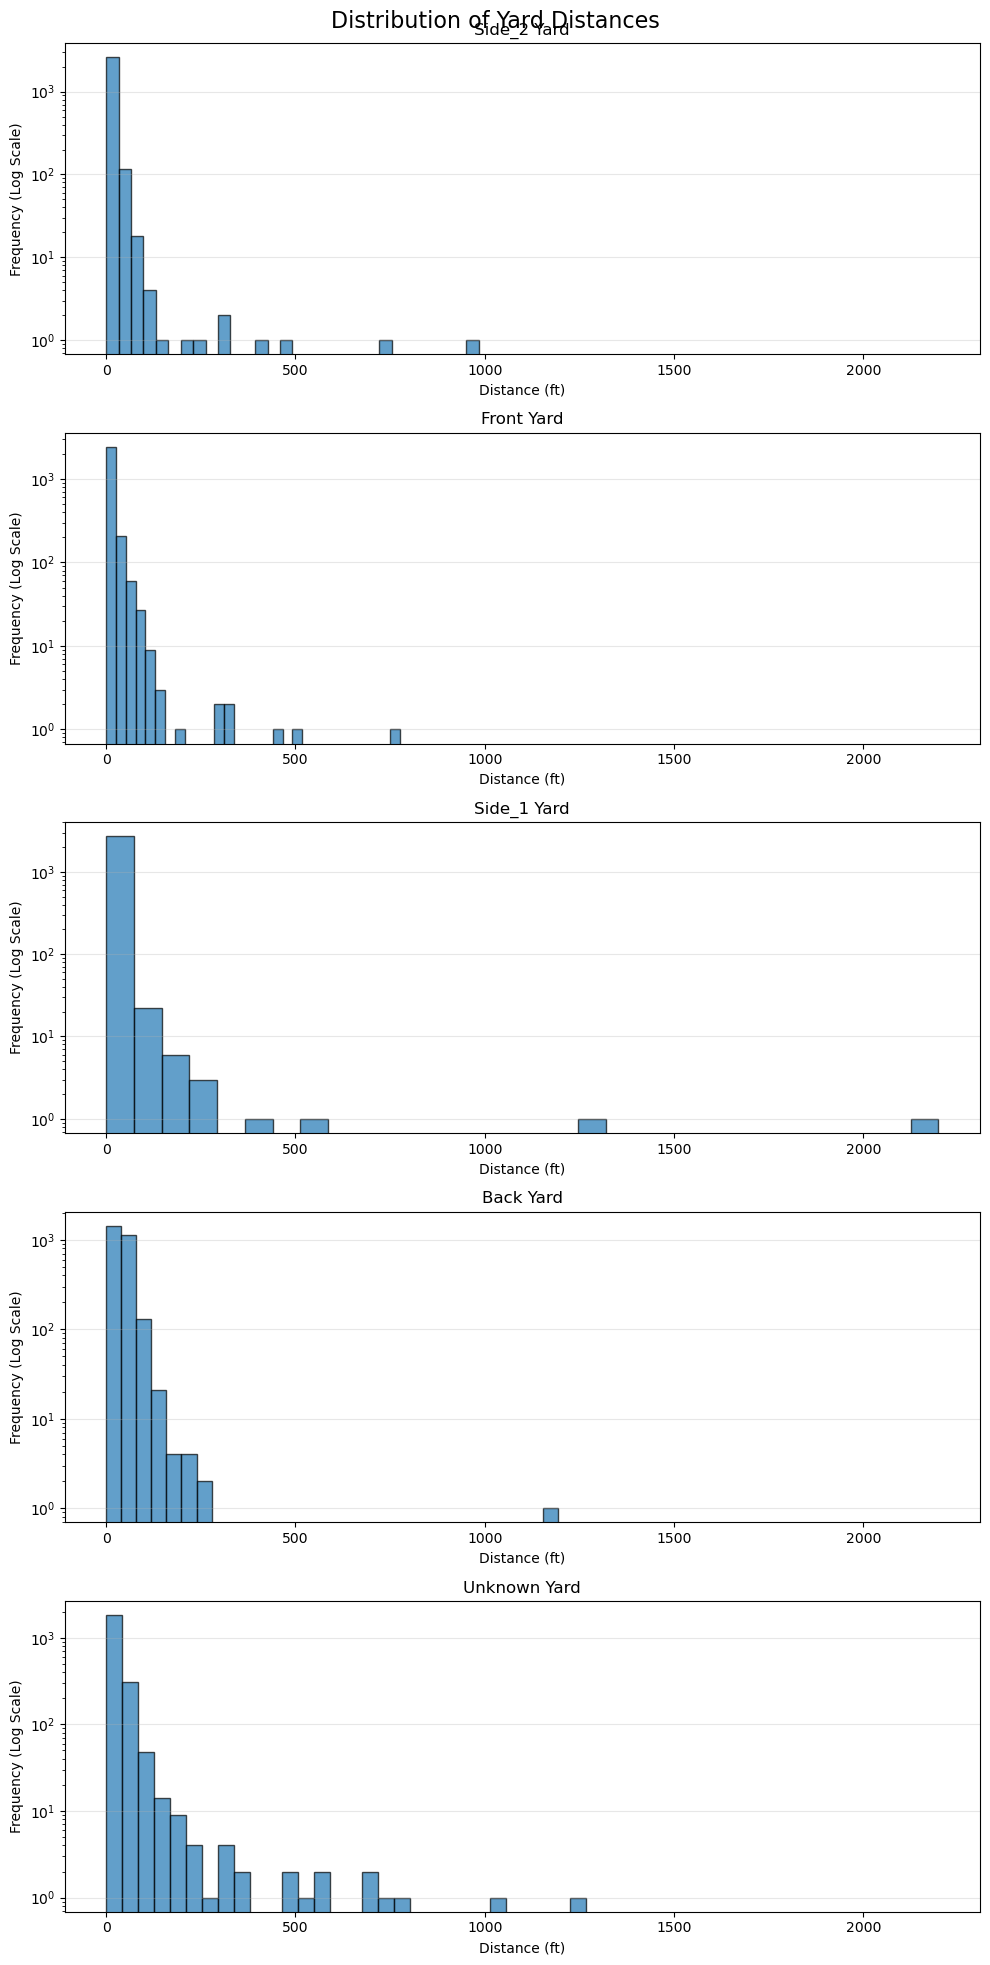

In [134]:
# plot the distribution of yard distances by yard type (front, back, side_1, side_2)
from matplotlib import pyplot as plt

yard_types = yard_distances_gdf["yard"].dropna().unique()

fig, axes = plt.subplots(
    nrows=len(yard_types),
    ncols=1,
    figsize=(10, 4 * len(yard_types)),
    sharex=True
)

if len(yard_types) == 1:
    axes = [axes]

for ax, yard_type in zip(axes, yard_types):
    data = yard_distances_gdf.loc[
        yard_distances_gdf["yard"] == yard_type,
        "distance_ft"
    ].dropna()

    ax.hist(data, bins=30, alpha=0.7, edgecolor="black", log=True)
    ax.set_title(f"{yard_type.title()} Yard")
    ax.set_xlabel("Distance (ft)")
    ax.set_ylabel("Frequency (Log Scale)")
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Distribution of Yard Distances", fontsize=16)
plt.tight_layout()
plt.show()

In [154]:
# plot parcels with their yard distances, classified edges and buildings
import random
import numpy as np


def _annotate_with_leader(ax, line, text, parcel_centroid, offset_ft=80):
    """
    Place a yard-distance label offset outward from the parcel (away from its
    centroid), joined to the middle of the yard line by a leader line.
    """
    (x0, y0), (x1, y1) = line.coords[0], line.coords[-1]
    mid_x, mid_y = (x0 + x1) / 2, (y0 + y1) / 2

    dx, dy = mid_x - parcel_centroid.x, mid_y - parcel_centroid.y
    norm = np.hypot(dx, dy)
    ux, uy = (dx / norm, dy / norm) if norm > 0 else (0.0, 1.0)

    ax.annotate(
        text,
        xy=(mid_x, mid_y),
        xytext=(mid_x + ux * offset_ft, mid_y + uy * offset_ft),
        textcoords="data",
        fontsize=7,
        color="blue",
        ha="center",
        va="center",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1),
        arrowprops=dict(arrowstyle="-", color="blue", lw=0.8, shrinkA=0, shrinkB=0),
        zorder=6,
    )


def draw_parcel_yard_distances(
    ax,
    parcel_id,
    yard_distances_gdf,
    classified_edges_gdf,
    parcels_gdf,
    streets_gdf,
    buildings_gdf,
    buffer_distance=100,
):
    """
    Draw one parcel on ax: roads, parcel, classified edges, buildings (primary
    highlighted) and the primary-building yard distance lines with leader-line
    labels. Returns False if the parcel could not be drawn.
    """
    ax = plot_parcel_edges(
        parcel_id=parcel_id,
        classified_edges_gdf=classified_edges_gdf,
        parcels_gdf=parcels_gdf,
        streets_gdf=streets_gdf,
        buffer_distance=buffer_distance,
        ax=ax,
    )
    if ax is None:
        return False

    parcel_geom = parcels_gdf.loc[
        parcels_gdf["MAP_PAR_ID"] == parcel_id, "geometry"
    ].iloc[0]
    if not parcel_geom.is_valid:
        parcel_geom = make_valid(parcel_geom)

    # Buildings whose representative point is inside this parcel
    nearby = buildings_gdf.loc[
        buildings_gdf.geometry.intersects(parcel_geom.buffer(buffer_distance))
    ]
    inside = nearby.loc[
        nearby.geometry.representative_point().within(parcel_geom).values
    ]
    is_primary = inside["is_primary_structure"] == 1

    other_buildings = inside.loc[~is_primary]
    if not other_buildings.empty:
        other_buildings.plot(
            ax=ax, facecolor="0.85", edgecolor="0.4", linewidth=0.8,
            alpha=0.9, label="Other building", zorder=2.5,
        )

    primary_buildings = inside.loc[is_primary]
    if not primary_buildings.empty:
        primary_buildings.plot(
            ax=ax, facecolor="orange", edgecolor="black", linewidth=1.5,
            alpha=0.9, label="Primary building", zorder=2.6,
        )

    # Yard distance lines from the primary building to each edge
    yard_lines = yard_distances_gdf[
        (yard_distances_gdf["MAP_PAR_ID"] == parcel_id)
        & (yard_distances_gdf["has_primary_building"])
    ]
    if not yard_lines.empty:
        yard_lines.plot(
            ax=ax, color="blue", linewidth=2.5, linestyle="--",
            label="Yard distance", zorder=5,
        )
        for _, row in yard_lines.iterrows():
            _annotate_with_leader(
                ax,
                row.geometry,
                f"{row['yard']}: {row['distance_ft']:.1f} ft",
                parcel_geom.centroid,
            )

    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, loc="upper right", fontsize=7)

    return True


def plot_parcels_with_yard_distances(
    parcel_ids,
    yard_distances_gdf,
    classified_edges_gdf,
    parcels_gdf,
    streets_gdf,
    buildings_gdf,
    buffer_distance=100,
    ncols=3,
):
    """
    Plot the given parcels in a grid, ncols wide, one parcel per cell.
    """
    n = len(parcel_ids)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
    axes = axes.flatten()

    for ax, parcel_id in zip(axes, parcel_ids):
        drawn = draw_parcel_yard_distances(
            ax, parcel_id, yard_distances_gdf, classified_edges_gdf,
            parcels_gdf, streets_gdf, buildings_gdf, buffer_distance,
        )
        if not drawn:
            ax.set_title(f"Parcel: {parcel_id}\nnot drawn (no edges or geometry)", fontsize=9)
            ax.set_axis_off()

    for ax in axes[n:]:
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()


def plot_random_parcels_with_yard_distances(
    yard_distances_gdf,
    classified_edges_gdf,
    parcels_gdf,
    streets_gdf,
    buildings_gdf,
    n=12,
    seed=None,
    buffer_distance=100,
    ncols=3,
):
    """
    Pick n random parcels that have a primary building and plot them in a grid.
    Returns the parcel IDs that were plotted.
    """
    candidates = (
        yard_distances_gdf.loc[yard_distances_gdf["has_primary_building"], "MAP_PAR_ID"]
        .drop_duplicates()
        .tolist()
    )
    chosen = random.Random(seed).sample(candidates, min(n, len(candidates)))
    print("Plotting parcels:", chosen)

    plot_parcels_with_yard_distances(
        chosen, yard_distances_gdf, classified_edges_gdf, parcels_gdf,
        streets_gdf, buildings_gdf, buffer_distance=buffer_distance, ncols=ncols,
    )
    return chosen


Plotting parcels: ['1802916000', '1404080000', '1800558000', '1802444000', '1800349010', '1800227000', '1803127000', '1802243000', '1403952000', '1404755000', '1405132000', '1801173000']


/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/var/folders/5g/711cf47n089grjr4zdhn8vb80000gn/T/ipykernel_79936/3413438632.py:106: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, labels = ax.get_legend_handles_labels()
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/building_codes/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in 

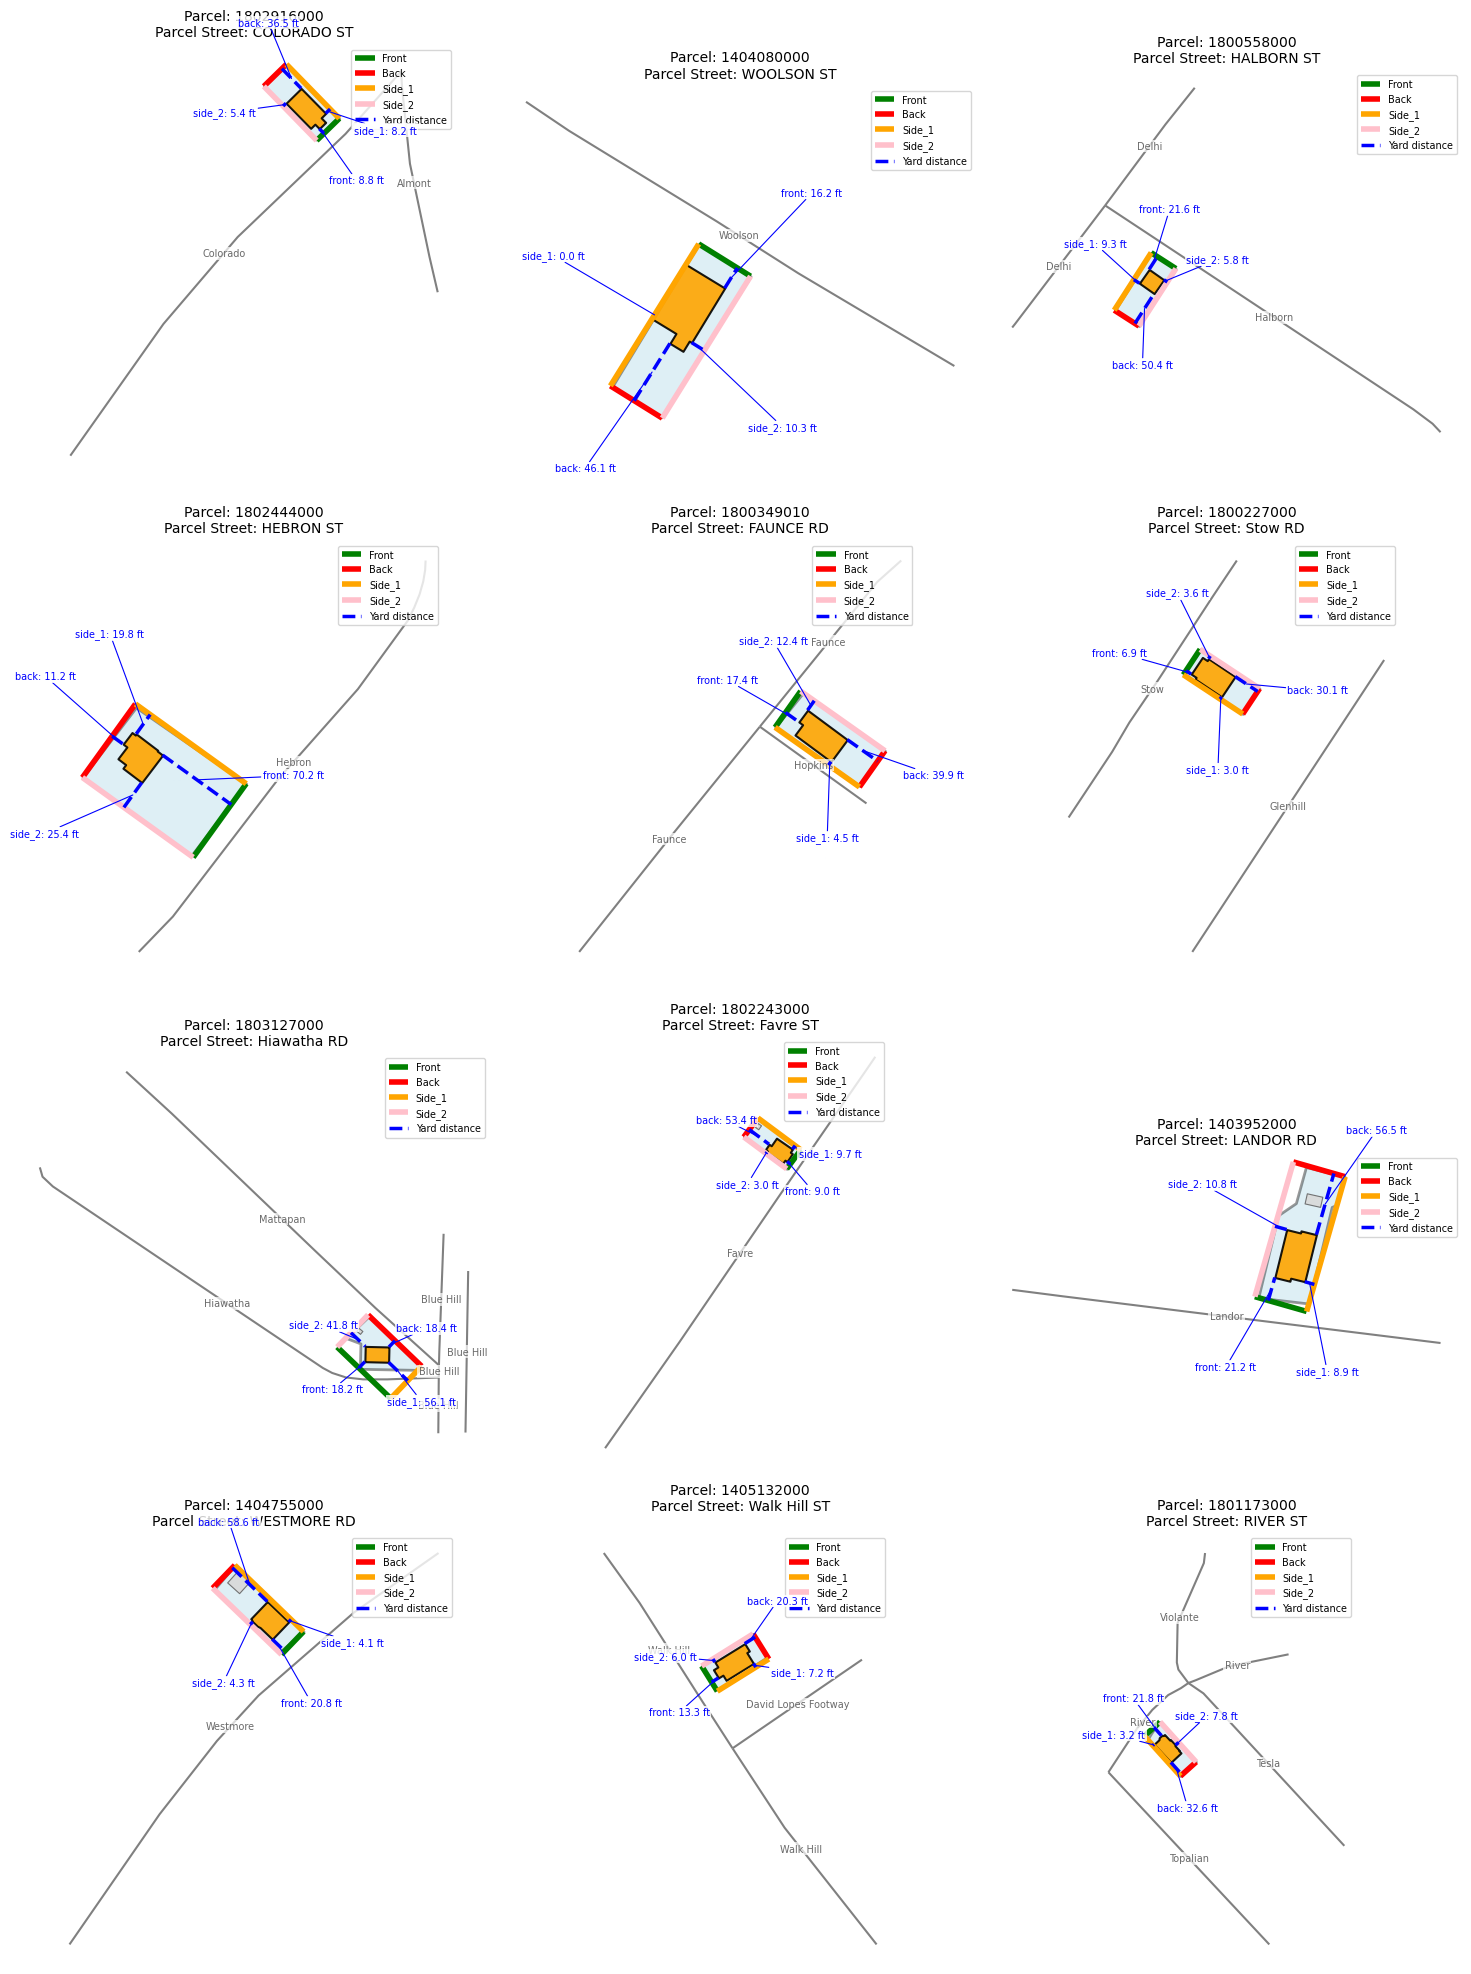

['1802916000',
 '1404080000',
 '1800558000',
 '1802444000',
 '1800349010',
 '1800227000',
 '1803127000',
 '1802243000',
 '1403952000',
 '1404755000',
 '1405132000',
 '1801173000']

In [158]:
plot_random_parcels_with_yard_distances(
    yard_distances_gdf,
    classified_edges_gdf,
    cleaned_parcels,
    streets_raw_gdf,
    buildings_raw_gdf,
    n=12,
    # seed=42,
    buffer_distance=100,
    ncols=3,
)

# OLD CODE

In [ ]:

# 1. Prepare streets with a combined ST_NAME and ST_TYPE
streets_combined = streets_gdf.copy()
streets_combined['COMBINED_ST_NAME'] = (
    streets_combined['ST_NAME'].fillna('').str.strip() + ' ' +
    streets_combined['ST_TYPE'].fillna('').str.strip()
).str.strip().str.upper()

# Filter parcels with valid street names
parcels_with_names = parcels_gdf[parcels_gdf['ST_NAME'].notna() & (parcels_gdf['ST_NAME'] != '')]

# 2. Select a random parcel sample
sample_parcel_row = parcels_with_names.sample(n=1)
sample_parcel_geom = sample_parcel_row.geometry.iloc[0]
parcel_st_name = sample_parcel_row['ST_NAME'].values[0].strip().upper()

# 3. Create a 0.1 mile buffer (0.1 miles = 528 feet since EPSG:2249 is in US feet)
# Let's project the parcel geometry to EPSG:2249 to do accurate distance/buffer math
sample_parcel_row_projected = sample_parcel_row.to_crs(epsg=2249)
sample_parcel_geom_projected = sample_parcel_row_projected.geometry.iloc[0]
buffer_geom = sample_parcel_geom_projected.buffer(528) # 0.1 miles in feet

# 4. Filter all streets within 0.1 miles of the parcel
# (streets_gdf is already in EPSG:2249)
streets_within_buffer = streets_combined[streets_combined.intersects(buffer_geom)]

# 5. Distinguish between matching street segments and other nearby segments
matching_streets = streets_within_buffer[streets_within_buffer['COMBINED_ST_NAME'] == parcel_st_name]
other_nearby_streets = streets_within_buffer[streets_within_buffer['COMBINED_ST_NAME'] != parcel_st_name]

# 6. Plot everything in EPSG:2249
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the other nearby roads within 0.1 miles in light grey
if not other_nearby_streets.empty:
    other_nearby_streets.plot(ax=ax, color='#D3D3D3', linewidth=2, label='Nearby Streets (0.1 mi)')

# Plot the matching street segment in blue
if not matching_streets.empty:
    matching_streets.plot(ax=ax, color='blue', linewidth=3, label=f'Matching Street ({parcel_st_name})')

# Plot the parcel in red
sample_parcel_row_projected.plot(ax=ax, color='red', alpha=0.6, edgecolor='black', label='Selected Parcel')

ax.set_title(f"Parcel ID: {sample_parcel_row_projected['MAP_PAR_ID'].values[0]}\nStreet: '{parcel_st_name}' & All Roads within 0.1 Miles")
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()

NameError: name 'streets_gdf' is not defined

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Polygon

# 1. Filter parcels with valid street names and project to EPSG:2249 for consistent geometric representation
parcels_with_names = parcels_gdf[parcels_gdf['ST_NAME'].notna() & (parcels_gdf['ST_NAME'] != '')]
parcels_projected = parcels_with_names.to_crs(epsg=2249)

# 2. Select a random parcel sample
sample_parcel_row = parcels_projected.sample(n=1)
sample_parcel_geom = sample_parcel_row.geometry.iloc[0]

# 3. Test if the parcel is four-sided (rectilinear)
is_four_sided = False
num_vertices = 0

if isinstance(sample_parcel_geom, Polygon):
    # Extract exterior coordinates; a 4-sided polygon has 5 coordinate pairs (including the repeating end node)
    coords = list(sample_parcel_geom.exterior.coords)
    num_vertices = len(coords) - 1  # Subtract 1 because the last coordinate closes the loop
    if len(coords) == 5:
        is_four_sided = True

print(f"Parcel ID: {sample_parcel_row['MAP_PAR_ID'].values[0]}")
print(f"Is the selected parcel 4-sided? {is_four_sided} (Number of unique vertices: {num_vertices})")

# 4. Plot the selected parcel
fig, ax = plt.subplots(figsize=(8, 8))
sample_parcel_row.plot(ax=ax, color='red', alpha=0.6, edgecolor='black')
ax.set_title(f"Selected Parcel (4-Sided: {is_four_sided}, Vertices: {num_vertices})")
plt.show()